# 03 — Experimento 1: baselines visuais

Classe majoritária e regressão logística sobre 6 estatísticas RGB — o piso de desempenho antes do MobileNetV2.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
M = ROOT / 'results' / 'metrics'
def show(name): display(Image(filename=str(ROOT / 'results' / name), width=620))


In [2]:
from src.ml import dataset as ds
from src.ml.run_all_experiments import make_head
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report
recs, _ = ds.clean_records(ds.list_records(ds.PLANTVILLAGE_DIR)); sp = ds.split_70_15_15(recs)
F = ds.extract_features(recs, 'plantvillage_features'); y = F['labels']; hc = F['handcrafted']
tr, te = sp['train'], sp['test']
maj = DummyClassifier(strategy='most_frequent').fit(hc[tr], y[tr])
base = make_head('logreg', c=0.03).fit(hc[tr][:, :6], y[tr])
print('Majoritária  acc = %.4f' % (maj.predict(hc[te]) == y[te]).mean())
print('6 RGB+LogReg acc = %.4f' % (base.predict(hc[te][:, :6]) == y[te]).mean())
print(classification_report(y[te], base.predict(hc[te][:, :6]), digits=3))

Majoritária  acc = 0.2479
6 RGB+LogReg acc = 0.6044
                             precision    recall  f1-score   support

Corn_(maize)___Common_rust_      0.888     0.935     0.911       170
      Potato___Early_blight      0.826     0.924     0.872       144
       Potato___Late_blight      0.645     0.340     0.445       144
      Tomato___Early_blight      0.507     0.511     0.509       141
       Tomato___Late_blight      0.337     0.379     0.356       272
           Tomato___healthy      0.631     0.650     0.641       226

                   accuracy                          0.604      1097
                  macro avg      0.639     0.623     0.622      1097
               weighted avg      0.609     0.604     0.600      1097



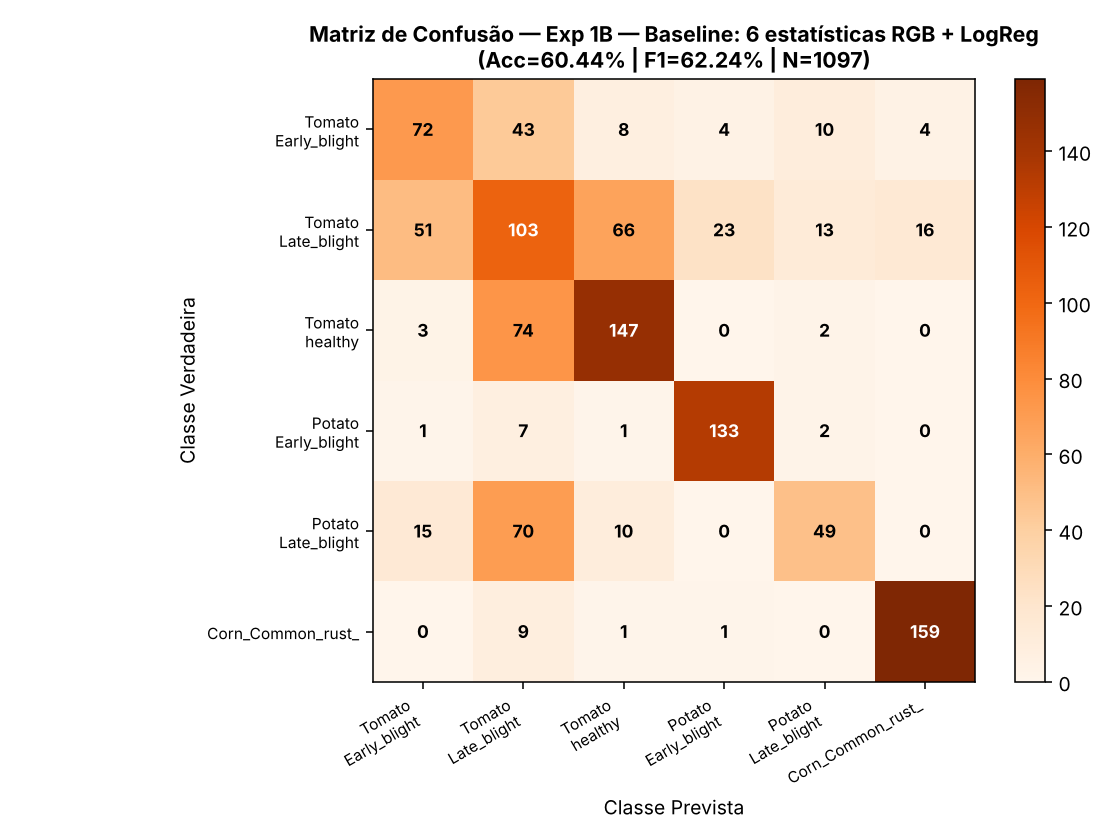

In [3]:
show('confusion_matrices/exp1_baseline_vision_cm.png')